In [6]:
##Data Manipulation

import pandas as pd
import numpy as np
df=pd.read_csv("Student.csv")
df.shape
df.isnull().sum()
df.duplicated().sum()
df.dtypes

,0
student_id,int64
attendance_pct,int64
homework_pct,int64
midterm_score,int64
study_hours_per_week,int64
pass,int64


In [10]:
##selecting the features and labels

x=df[["attendance_pct",
      "homework_pct",
     "midterm_score",
     "study_hours_per_week"]]
y=df["pass"]
x.shape,y.shape

((100, 4), (100,))

In [12]:
##Train the model

from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((80, 4), (20, 4), (80,), (20,))

In [13]:
##model trainig

from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(x_train,y_train)

LogisticRegression()

In [16]:
##make predictions

y_pred=model.predict(x_test)
y_pred

array([1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1])

In [17]:
##metrics

from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
accuracy_score(y_test,y_pred)
confusion_matrix(y_test,y_pred)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00        12

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



[[ 8  0]
 [ 0 12]]


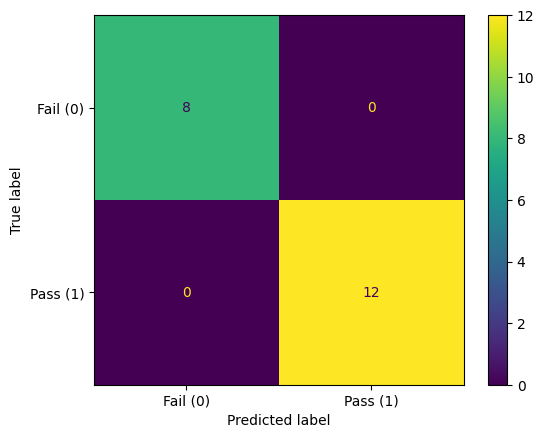

In [18]:
##confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Fail (0)', 'Pass (1)']
)

disp.plot()
plt.show()

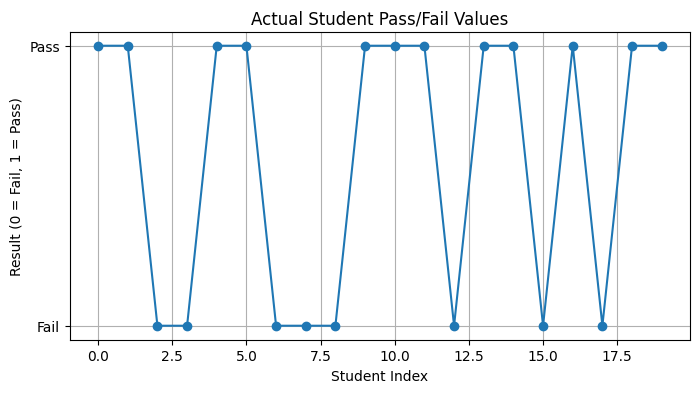

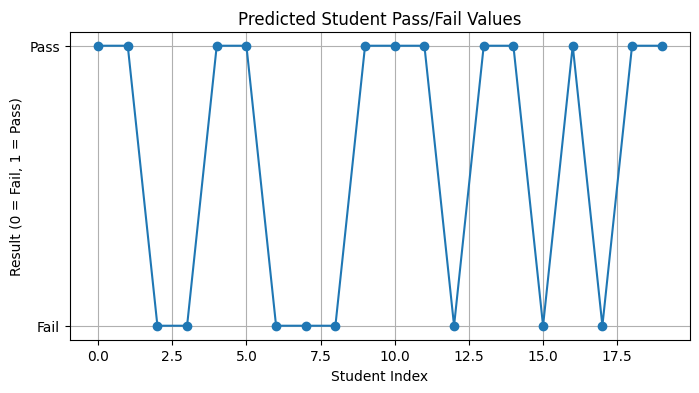

In [19]:
import matplotlib.pyplot as plt

# Actual values
plt.figure(figsize=(8, 4))
plt.plot(range(len(y_test)), y_test, marker='o')
plt.title("Actual Student Pass/Fail Values")
plt.xlabel("Student Index")
plt.ylabel("Result (0 = Fail, 1 = Pass)")
plt.yticks([0, 1], ["Fail", "Pass"])
plt.grid(True)
plt.show()


# Predicted values
plt.figure(figsize=(8, 4))
plt.plot(range(len(y_pred)), y_pred, marker='o')
plt.title("Predicted Student Pass/Fail Values")
plt.xlabel("Student Index")
plt.ylabel("Result (0 = Fail, 1 = Pass)")
plt.yticks([0, 1], ["Fail", "Pass"])
plt.grid(True)
plt.show()